# **3. Класифікація текстів за допомогою рекурентних нейронних мереж**

У цій частині лабораторної роботи досліджується застосування рекурентних нейронних мереж для класифікації текстових даних. Такі мережі дають змогу враховувати послідовність слів у тексті та використовувати контекст для визначення його тематичної категорії.

Для експерименту використовується датасет BBC News, який містить новинні статті п'яти категорій: `business`, `entertainment`, `politics`, `sport` і `tech` . Завдання полягає у визначенні тематичної категорії новини за її текстом.

У роботі буде реалізовано дві моделі на основі LSTM: першу з Embedding-шаром із випадковою ініціалізацією ваг, другу — з використанням попередньо навчених векторних представлень слів GloVe. Це дасть змогу порівняти ефективність навчання власних векторних представлень із використанням попередньо навчених embeddings.


In [1]:


from datasets import load_dataset
import pandas as pd

dataset = load_dataset("SetFit/bbc-news")

print("Структура датасету:")
print(dataset)

for split_name, split_data in dataset.items():
    print(f"\n{'=' * 50}")
    print(f"Вибірка: {split_name}")
    print(f"Кількість записів: {len(split_data)}")
    print(f"Поля: {split_data.column_names}")
    print(f"Типи полів: {split_data.features}")

    if "label_text" in split_data.column_names:
        labels = split_data["label_text"]
    elif "label" in split_data.column_names:
        labels = split_data["label"]
    else:
        labels = None

    if labels is not None:
        print("\nРозподіл класів:")
        print(pd.Series(labels).value_counts().sort_index())

print("\nПриклад запису:")
print(dataset["train"][0])


Структура датасету:
DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 1225
    })
    test: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 1000
    })
})

Вибірка: train
Кількість записів: 1225
Поля: ['text', 'label', 'label_text']
Типи полів: {'text': Value('string'), 'label': Value('int64'), 'label_text': Value('string')}

Розподіл класів:
business         286
entertainment    210
politics         242
sport            275
tech             212
Name: count, dtype: int64

Вибірка: test
Кількість записів: 1000
Поля: ['text', 'label', 'label_text']
Типи полів: {'text': Value('string'), 'label': Value('int64'), 'label_text': Value('string')}

Розподіл класів:
business         224
entertainment    176
politics         175
sport            236
tech             189
Name: count, dtype: int64

Приклад запису:
{'text': 'wales want rugby league training wales could follow england s lead by training with a rugby 

# **3.2 Попередня обробка текстових даних**

In [2]:

# Поділ даних, токенізація та побудова словника

import re
from collections import Counter
from sklearn.model_selection import train_test_split

train_texts = dataset["train"]["text"]
train_labels_text = dataset["train"]["label_text"]

test_texts = dataset["test"]["text"]
test_labels_text = dataset["test"]["label_text"]

class_names = sorted(set(train_labels_text))
label2id = {label: idx for idx, label in enumerate(class_names)}
id2label = {idx: label for label, idx in label2id.items()}

train_labels = [label2id[label] for label in train_labels_text]
test_labels = [label2id[label] for label in test_labels_text]

train_texts, val_texts, train_labels, val_labels = train_test_split(
    train_texts,
    train_labels,
    test_size=0.2,
    random_state=42,
    stratify=train_labels
)

def tokenize(text):
    return re.findall(r"\b\w+\b", text.lower())

train_tokens = [tokenize(text) for text in train_texts]
val_tokens = [tokenize(text) for text in val_texts]
test_tokens = [tokenize(text) for text in test_texts]

# Побудова словника тільки за навчальними текстами
counter = Counter(token for text in train_tokens for token in text)

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

vocab = {
    PAD_TOKEN: 0,
    UNK_TOKEN: 1
}

for word, frequency in counter.most_common(20000 - len(vocab)):
    if frequency >= 2:
        vocab[word] = len(vocab)

train_lengths = [len(tokens) for tokens in train_tokens]
max_len = min(400, int(sorted(train_lengths)[int(0.95 * len(train_lengths))]))

print("Кількість класів:", len(class_names))
print("Класи:", class_names)
print(f"\nРозмір train: {len(train_texts)}")
print(f"Розмір validation: {len(val_texts)}")
print(f"Розмір test: {len(test_texts)}")
print(f"\nРозмір словника: {len(vocab)}")
print(f"Максимальна довжина послідовності: {max_len}")
print(f"Середня довжина тексту: {sum(train_lengths) / len(train_lengths):.1f} токенів")
print(f"95-й перцентиль довжини: {sorted(train_lengths)[int(0.95 * len(train_lengths))]} токенів")


Кількість класів: 5
Класи: ['business', 'entertainment', 'politics', 'sport', 'tech']

Розмір train: 980
Розмір validation: 245
Розмір test: 1000

Розмір словника: 12968
Максимальна довжина послідовності: 400
Середня довжина тексту: 399.7 токенів
95-й перцентиль довжини: 746 токенів


# **3.3 Перетворення текстів на числові послідовності**

Для використання текстових даних у PyTorch необхідно перетворити кожне слово на відповідний індекс зі словника. Усі послідовності приводяться до однакової довжини за допомогою padding і truncation. Після цього сформуємо DataLoader для пакетного навчання моделей.

In [3]:

# Перетворення текстів на індекси та підготовка DataLoader

import torch
from torch.utils.data import TensorDataset, DataLoader

def encode_text(tokens):
    ids = [vocab.get(token, vocab[UNK_TOKEN]) for token in tokens]
    ids = ids[:max_len]
    ids += [vocab[PAD_TOKEN]] * (max_len - len(ids))
    return ids

# Формування тензорів
X_train = torch.tensor([encode_text(t) for t in train_tokens], dtype=torch.long)
X_val = torch.tensor([encode_text(t) for t in val_tokens], dtype=torch.long)
X_test = torch.tensor([encode_text(t) for t in test_tokens], dtype=torch.long)

y_train = torch.tensor(train_labels, dtype=torch.long)
y_val = torch.tensor(val_labels, dtype=torch.long)
y_test = torch.tensor(test_labels, dtype=torch.long)

# Створення наборів даних
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

BATCH_SIZE = 32

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("Розмір тензора train:", X_train.shape)
print("Розмір тензора validation:", X_val.shape)
print("Розмір тензора test:", X_test.shape)

batch_texts, batch_labels = next(iter(train_loader))
print("\nРозмір одного пакета текстів:", batch_texts.shape)
print("Розмір пакета міток:", batch_labels.shape)
print("Діапазон індексів слів:", X_train.min().item(), "-", X_train.max().item())


Розмір тензора train: torch.Size([980, 400])
Розмір тензора validation: torch.Size([245, 400])
Розмір тензора test: torch.Size([1000, 400])

Розмір одного пакета текстів: torch.Size([32, 400])
Розмір пакета міток: torch.Size([32])
Діапазон індексів слів: 0 - 12966


# **3.4 LSTM із випадковими Embeddings**

На першому етапі реалізуємо двонапрямлену рекурентну нейронну мережу BiLSTM. Шар Embedding матиме випадково ініціалізовані ваги, які навчатимуться разом із мережею. Для класифікації використовуватимемо вихідні стани LSTM в обох напрямках.

Під час навчання контролюватимемо втрати та точність на навчальній і валідаційній вибірках. Для запобігання перенавчанню застосуємо Early Stopping зі збереженням найкращої моделі за значенням validation loss.

In [7]:

import copy
import time
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import TensorDataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence

# Фіксація випадковості
torch.manual_seed(42)

MAX_LEN = 250
BATCH_SIZE = 32
EPOCHS = 12
PATIENCE = 3
EMBEDDING_DIM = 100
HIDDEN_DIM = 64

device = torch.device("cpu")
print("Обчислювальний пристрій:", device)

# Перетворення текстів на індекси
def prepare_sequences(tokens):
    sequences, lengths = [], []

    for text in tokens:
        ids = [vocab.get(token, vocab[UNK_TOKEN]) for token in text[:MAX_LEN]]
        lengths.append(max(len(ids), 1))
        ids += [vocab[PAD_TOKEN]] * (MAX_LEN - len(ids))
        sequences.append(ids)

    return (
        torch.tensor(sequences, dtype=torch.long),
        torch.tensor(lengths, dtype=torch.long)
    )

X_train_cpu, len_train_cpu = prepare_sequences(train_tokens)
X_val_cpu, len_val_cpu = prepare_sequences(val_tokens)
X_test_cpu, len_test_cpu = prepare_sequences(test_tokens)

train_loader = DataLoader(
    TensorDataset(X_train_cpu, y_train, len_train_cpu),
    batch_size=BATCH_SIZE, shuffle=True
)

val_loader = DataLoader(
    TensorDataset(X_val_cpu, y_val, len_val_cpu),
    batch_size=BATCH_SIZE
)

test_loader = DataLoader(
    TensorDataset(X_test_cpu, y_test, len_test_cpu),
    batch_size=BATCH_SIZE
)

print("Train:", X_train_cpu.shape)
print("Validation:", X_val_cpu.shape)
print("Test:", X_test_cpu.shape)


# Архітектура BiLSTM
class TextLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim=100,
                 hidden_dim=64, num_classes=5, embedding_matrix=None):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size, embedding_dim, padding_idx=0
        )

        if embedding_matrix is not None:
            self.embedding.weight.data.copy_(embedding_matrix)

        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(0.4)
        self.fc = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, x, lengths):
        embedded = self.embedding(x)

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, (hidden, _) = self.lstm(packed)

        features = torch.cat((hidden[-2], hidden[-1]), dim=1)
        return self.fc(self.dropout(features))


# Універсальна функція навчання
def train_model(model, train_loader, val_loader,
                epochs=EPOCHS, patience=PATIENCE):

    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    history = {
        "train_loss": [], "val_loss": [],
        "train_acc": [], "val_acc": []
    }

    best_loss = float("inf")
    best_state = None
    wait = 0
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        total_loss, correct, total = 0, 0, 0

        for texts, labels, lengths in train_loader:
            optimizer.zero_grad(set_to_none=True)

            outputs = model(texts, lengths)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

        train_loss = total_loss / total
        train_acc = correct / total

        model.eval()
        val_total_loss, val_correct, val_total = 0, 0, 0

        with torch.no_grad():
            for texts, labels, lengths in val_loader:
                outputs = model(texts, lengths)
                loss = criterion(outputs, labels)

                val_total_loss += loss.item() * labels.size(0)
                val_correct += (outputs.argmax(1) == labels).sum().item()
                val_total += labels.size(0)

        val_loss = val_total_loss / val_total
        val_acc = val_correct / val_total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(
            f"Епоха {epoch+1:02d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

        if val_loss < best_loss:
            best_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print("Early Stopping: навчання зупинено.")
                break

    model.load_state_dict(best_state)
    elapsed = time.time() - start_time

    print(f"\nЧас навчання: {elapsed:.1f} секунд")
    print(f"Найкраща Validation Loss: {best_loss:.4f}")

    return model, history, elapsed


# Створення та навчання моделі з випадковими Embeddings
model_random = TextLSTM(
    vocab_size=len(vocab),
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_classes=len(class_names)
)

model_random, history_random, time_random = train_model(
    model_random, train_loader, val_loader
)


Обчислювальний пристрій: cpu
Train: torch.Size([980, 250])
Validation: torch.Size([245, 250])
Test: torch.Size([1000, 250])
Епоха 01/12 | Train Loss: 1.5949 | Val Loss: 1.5888 | Train Acc: 0.2469 | Val Acc: 0.2776
Епоха 02/12 | Train Loss: 1.5105 | Val Loss: 1.5496 | Train Acc: 0.4122 | Val Acc: 0.3429
Епоха 03/12 | Train Loss: 1.4063 | Val Loss: 1.4950 | Train Acc: 0.5469 | Val Acc: 0.4122
Епоха 04/12 | Train Loss: 1.2293 | Val Loss: 1.3104 | Train Acc: 0.6490 | Val Acc: 0.4939
Епоха 05/12 | Train Loss: 0.9088 | Val Loss: 1.1786 | Train Acc: 0.7367 | Val Acc: 0.5878
Епоха 06/12 | Train Loss: 0.5883 | Val Loss: 0.9592 | Train Acc: 0.8796 | Val Acc: 0.6612
Епоха 07/12 | Train Loss: 0.3210 | Val Loss: 0.8718 | Train Acc: 0.9367 | Val Acc: 0.6980
Епоха 08/12 | Train Loss: 0.1831 | Val Loss: 1.0231 | Train Acc: 0.9684 | Val Acc: 0.6408
Епоха 09/12 | Train Loss: 0.1446 | Val Loss: 0.8244 | Train Acc: 0.9827 | Val Acc: 0.7469
Епоха 10/12 | Train Loss: 0.0777 | Val Loss: 0.8256 | Train Acc: 0


### **Аналіз результатів BiLSTM із випадковими Embeddings**

Під час навчання моделі спостерігалося поступове зменшення функції втрат та зростання точності на навчальній вибірці. Наприкінці навчання Train Accuracy досягла 99,49%, тоді як Validation Accuracy становила 72,65%.

Найвище значення Validation Accuracy — 74,69% — було отримано на 9-й епосі. Найменше значення Validation Loss становило 0,7785 на 12-й епосі.

Значна різниця між точністю на навчальній та валідаційній вибірках свідчить про перенавчання моделі. Це може бути пов'язано з обмеженим обсягом навчальних даних та необхідністю самостійного формування векторних представлень слів.

Отримані результати будуть використані для порівняння з моделлю, що використовує попередньо навчені GloVe Embeddings.


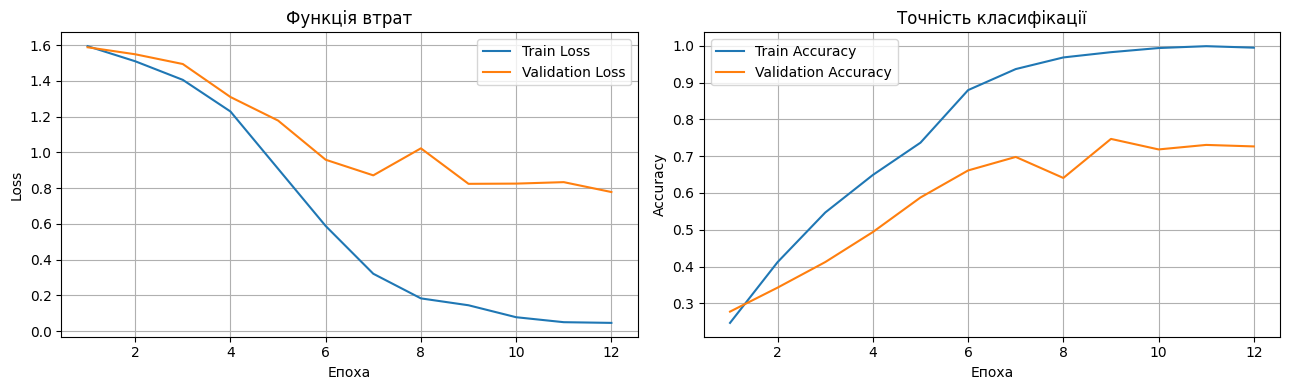

In [8]:

# Візуалізація процесу навчання BiLSTM

epochs_range = range(1, len(history_random["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(epochs_range, history_random["train_loss"], label="Train Loss")
axes[0].plot(epochs_range, history_random["val_loss"], label="Validation Loss")
axes[0].set_title("Функція втрат")
axes[0].set_xlabel("Епоха")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid()

axes[1].plot(epochs_range, history_random["train_acc"], label="Train Accuracy")
axes[1].plot(epochs_range, history_random["val_acc"], label="Validation Accuracy")
axes[1].set_title("Точність класифікації")
axes[1].set_xlabel("Епоха")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()


# **3.5 BiLSTM із попередньо навченими GloVe Embeddings**

На другому етапі використаємо попередньо навчені векторні представлення слів GloVe розмірністю 100. Вони містять інформацію про семантичні та контекстуальні зв'язки між словами, отриману під час попереднього навчання на великому текстовому корпусі.

На основі цих векторів буде сформовано матрицю ініціалізації Embedding-шару. Для слів, відсутніх у попередньо навченому словнику, використовуватимуться випадкові вектори.

Архітектура BiLSTM, параметри навчання та розбиття даних залишаються такими самими, як у першій моделі. Це забезпечить коректність порівняння двох підходів.

In [9]:


import numpy as np
import gensim.downloader as api

print("Завантаження GloVe...")
glove = api.load("glove-wiki-gigaword-100")

# Формування матриці Embeddings
torch.manual_seed(42)

embedding_matrix = np.random.normal(
    0, 0.1, (len(vocab), EMBEDDING_DIM)
).astype(np.float32)

embedding_matrix[vocab[PAD_TOKEN]] = 0

found = 0

for word, idx in vocab.items():
    if word in glove:
        embedding_matrix[idx] = glove[word]
        found += 1

embedding_matrix = torch.tensor(embedding_matrix, dtype=torch.float32)

print(f"Слів у словнику: {len(vocab)}")
print(f"Знайдено в GloVe: {found}")
print(f"Покриття словника: {found / len(vocab) * 100:.2f}%")

# Створення моделі з GloVe Embeddings
torch.manual_seed(42)

model_glove = TextLSTM(
    vocab_size=len(vocab),
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_classes=len(class_names),
    embedding_matrix=embedding_matrix
)

model_glove, history_glove, time_glove = train_model(
    model_glove, train_loader, val_loader
)

# Звільнення пам'яті після використання GloVe
del glove, embedding_matrix


Завантаження GloVe...
[==================================================] 100.0% 128.1/128.1MB downloaded
Слів у словнику: 12968
Знайдено в GloVe: 12754
Покриття словника: 98.35%
Епоха 01/12 | Train Loss: 1.4868 | Val Loss: 1.2371 | Train Acc: 0.4306 | Val Acc: 0.6612
Епоха 02/12 | Train Loss: 0.8399 | Val Loss: 0.5311 | Train Acc: 0.7347 | Val Acc: 0.8571
Епоха 03/12 | Train Loss: 0.5268 | Val Loss: 0.4027 | Train Acc: 0.8347 | Val Acc: 0.9102
Епоха 04/12 | Train Loss: 0.3294 | Val Loss: 0.2868 | Train Acc: 0.9184 | Val Acc: 0.9306
Епоха 05/12 | Train Loss: 0.2558 | Val Loss: 0.3673 | Train Acc: 0.9337 | Val Acc: 0.8939
Епоха 06/12 | Train Loss: 0.2467 | Val Loss: 0.2412 | Train Acc: 0.9255 | Val Acc: 0.9306
Епоха 07/12 | Train Loss: 0.2221 | Val Loss: 0.3096 | Train Acc: 0.9327 | Val Acc: 0.8898
Епоха 08/12 | Train Loss: 0.1842 | Val Loss: 0.1857 | Train Acc: 0.9520 | Val Acc: 0.9551
Епоха 09/12 | Train Loss: 0.1083 | Val Loss: 0.1752 | Train Acc: 0.9786 | Val Acc: 0.9510
Епоха 10/1


### **Аналіз результатів BiLSTM із GloVe Embeddings**

Використання попередньо навчених векторних представлень GloVe суттєво покращило результати класифікації текстів.

Покриття словника попередньо навченими векторами становило 98,35% (12 754 із 12 968 слів). Під час навчання найменше значення Validation Loss становило 0,1199, а найвища Validation Accuracy досягла 96,33% на 10-й епосі.

Порівняно з моделлю, що використовувала випадково ініціалізовані Embeddings, точність на валідаційній вибірці зросла на 21,64 відсоткового пункту.

Отримані результати свідчать про перевагу попередньо навчених векторних представлень слів для цієї задачі. Незважаючи на коливання метрик наприкінці навчання, модель із GloVe продемонструвала кращу збіжність і вищу якість класифікації.


# **3.6 Оцінювання моделей на тестовій вибірці та порівняння результатів**

Порівняння моделей на тестовій вибірці:


,Random Embeddings,GloVe Embeddings
Accuracy,0.7390,0.9420
Macro Precision,0.7370,0.9394
Macro Recall,0.7336,0.9406
Macro F1-score,0.7345,0.9397
Training time (sec),678.0637,537.7595



Random Embeddings:
               precision    recall  f1-score   support

     business       0.70      0.79      0.74       224
entertainment       0.68      0.69      0.69       176
     politics       0.79      0.75      0.77       175
        sport       0.83      0.81      0.82       236
         tech       0.69      0.63      0.66       189

     accuracy                           0.74      1000
    macro avg       0.74      0.73      0.73      1000
 weighted avg       0.74      0.74      0.74      1000


GloVe Embeddings:
               precision    recall  f1-score   support

     business       0.95      0.94      0.94       224
entertainment       0.89      0.96      0.93       176
     politics       0.93      0.91      0.92       175
        sport       0.99      0.97      0.98       236
         tech       0.94      0.92      0.93       189

     accuracy                           0.94      1000
    macro avg       0.94      0.94      0.94      1000
 weighted avg       0

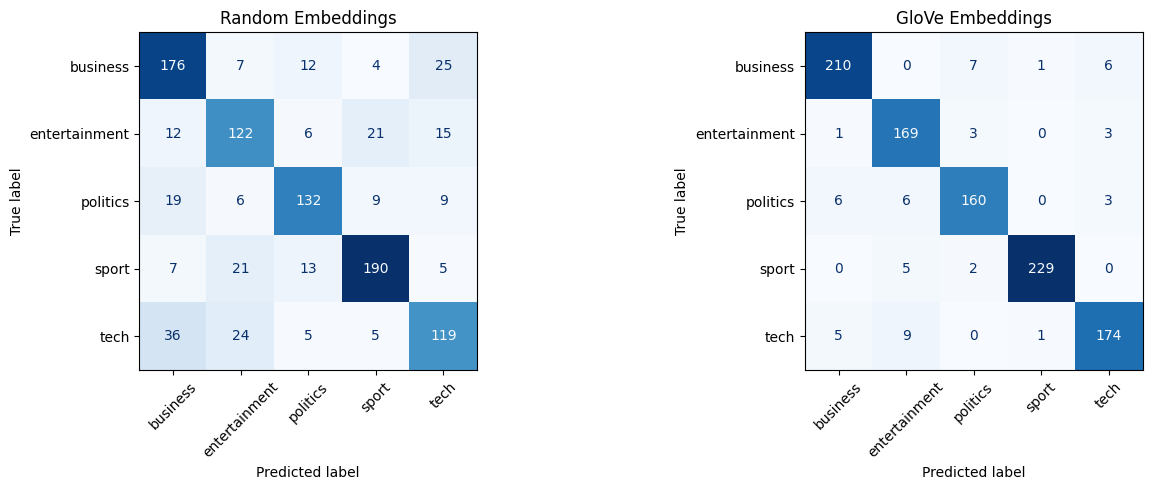

In [10]:


from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)
import pandas as pd
import matplotlib.pyplot as plt

def evaluate_model(model, loader):
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for texts, labels, lengths in loader:
            outputs = model(texts, lengths)
            predictions = outputs.argmax(dim=1)

            y_true.extend(labels.numpy())
            y_pred.extend(predictions.numpy())

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="macro"),
        "Recall": recall_score(y_true, y_pred, average="macro"),
        "F1-score": f1_score(y_true, y_pred, average="macro"),
        "y_true": y_true,
        "y_pred": y_pred
    }


results_random = evaluate_model(model_random, test_loader)
results_glove = evaluate_model(model_glove, test_loader)

comparison = pd.DataFrame({
    "Random Embeddings": [
        results_random["Accuracy"],
        results_random["Precision"],
        results_random["Recall"],
        results_random["F1-score"],
        time_random
    ],
    "GloVe Embeddings": [
        results_glove["Accuracy"],
        results_glove["Precision"],
        results_glove["Recall"],
        results_glove["F1-score"],
        time_glove
    ]
}, index=[
    "Accuracy", "Macro Precision", "Macro Recall",
    "Macro F1-score", "Training time (sec)"
])

print("Порівняння моделей на тестовій вибірці:")
display(comparison.round(4))

print("\nRandom Embeddings:")
print(classification_report(
    results_random["y_true"],
    results_random["y_pred"],
    target_names=class_names,
    zero_division=0
))

print("\nGloVe Embeddings:")
print(classification_report(
    results_glove["y_true"],
    results_glove["y_pred"],
    target_names=class_names,
    zero_division=0
))

# Матриці помилок
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, results, title in [
    (axes[0], results_random, "Random Embeddings"),
    (axes[1], results_glove, "GloVe Embeddings")
]:
    ConfusionMatrixDisplay(
        confusion_matrix(results["y_true"], results["y_pred"]),
        display_labels=class_names
    ).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)

    ax.set_title(title)

plt.tight_layout()
plt.show()



### **ВИСНОВКИ**

У третій частині лабораторної роботи було досліджено застосування рекурентних нейронних мереж для класифікації текстів на прикладі датасету BBC News, який містить п'ять тематичних категорій: business, entertainment, politics, sport і tech.

Було реалізовано дві двонапрямлені рекурентні мережі BiLSTM, які відрізнялися способом ініціалізації Embedding-шару. Перша модель використовувала випадково ініціалізовані векторні представлення слів, а друга — попередньо навчені GloVe Embeddings розмірністю 100.

Для першої моделі на тестовій вибірці отримано Accuracy 73,90% та Macro F1-score 73,45%. Використання попередньо навчених GloVe Embeddings дозволило підвищити Accuracy до 94,20%, а Macro F1-score — до 93,97%. Таким чином, точність класифікації зросла на 20,30 відсоткового пункту.

Покриття словника попередньо навченими векторами GloVe становило 98,35%. Крім того, час навчання другої моделі був меншим: 537,8 секунди порівняно з 678,1 секунди для моделі з випадковими Embeddings.

Аналіз матриць помилок показав, що модель із GloVe Embeddings краще класифікує тексти всіх п'яти категорій та допускає значно менше помилок. Отримані результати підтверджують ефективність використання попередньо навчених векторних представлень слів для задачі класифікації текстів.

Отже, у межах проведеного експерименту модель BiLSTM із GloVe Embeddings продемонструвала кращу якість класифікації та менший час навчання порівняно з моделлю, яка використовувала випадково ініціалізовані Embeddings.
